# Experimentos extras: o que as aulas pedem além do KNN básico

**CIN0208 – Ciência de Dados · Equipe 5** · continuação do `02_Modelagem_KNN`

O notebook 02 montou o pipeline, a validação por posto e a grade de 360 experimentos. Aqui testamos, **um tema por vez e sempre contra a mesma base (base v1)**, o que as aulas ensinam:

| Seção | Tema | Aula |
|---|---|---|
| 1 | Baseline (classe majoritária) | 3 |
| 2 | Dados ausentes: o que significa "-"? | 5 |
| 3 | Valores incorretos, duplicatas e outliers | 5 |
| 4 | Encoding | 6 |
| 5 | Normalização (5 scalers) | 6 |
| 6 | Seleção de atributos e PCA | 7 |
| 7 | Balanceamento de classes | 8 |
| 8 | Pipeline final combinado e tabela geral | 2, 3 |

**Regra de ouro:** tudo que aprende dos dados (imputação, scaler, seleção, PCA, reamostragem) fica **dentro do Pipeline ou só no treino de cada fold**. Assim o teste nunca "espia" o treino.

## 0. Preparação (mesmas células do notebook 02)

In [1]:
!pip install -q imbalanced-learn 2>/dev/null || true   # só no Colab; se falhar, usamos uma versão própria dos reamostradores

In [2]:
import os, re, time, itertools, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer, KNNImputer
from sklearn.preprocessing import StandardScaler, MinMaxScaler, RobustScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import StratifiedGroupKFold, cross_validate, cross_val_predict
from sklearn.metrics import classification_report, confusion_matrix

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
SEED = 42          # semente fixa: o resultado pode ser reproduzido
RODAR_GRADE = True # True = roda os 360 experimentos (~6 min); False = lê os resultados já salvos

In [3]:
NOME = "Dataset APAC - Página1.csv"
URL  = ("https://raw.githubusercontent.com/mateuscresp/CienciaDados-Equipe5-Projeto/"
        "main/data/raw/Dataset%20APAC%20-%20P%C3%A1gina1.csv")

if os.path.exists(NOME):
    caminho = NOME
elif os.path.exists("data/raw/" + NOME):
    caminho = "data/raw/" + NOME
else:
    caminho = URL   # se falhar, suba o CSV no Colab (ícone de pasta) e rode de novo

df = pd.read_csv(caminho)
print("Dimensões:", df.shape)
df.head(3)

Dimensões: (5104, 16)


,Código,Posto,Ano,Janeiro,Fevereiro,Março,Abril,Maio,Junho,Julho,Agosto,Setembro,Outubro,Novembro,Dezembro,Meses ausentes
0,198,Abreu e Lima,2010,"83,5","44,4","69,2","188,4","142,8","258,4","158,4","43,7","52,2","15,9","10,1","46,4",0
1,290,Afogados da Ingazeira,2010,145,62,41,147,"1,5","74,7","17,5",-,-,"185,5",-,"29,5",3
2,377,Afogados da Ingazeira (Açude Brotas),2010,"120,2","58,5","30,5",122,"1,5","72,7","15,7",-,-,"162,2",-,"37,4",3


In [4]:
MESES = ['Janeiro', 'Fevereiro', 'Março', 'Abril', 'Maio', 'Junho',
         'Julho', 'Agosto', 'Setembro', 'Outubro', 'Novembro', 'Dezembro']

meso_map = {
    # Metropolitana do Recife
    'Abreu e Lima': 'Metropolitana do Recife', 'Araçoiaba': 'Metropolitana do Recife',
    'Cabo': 'Metropolitana do Recife', 'Cabo de Santo Agostinho': 'Metropolitana do Recife',
    'Camaragibe': 'Metropolitana do Recife', 'Igarassu': 'Metropolitana do Recife',
    'Itamaracá': 'Metropolitana do Recife', 'Ipojuca': 'Metropolitana do Recife',
    'Itapissuma': 'Metropolitana do Recife', 'Jaboatão': 'Metropolitana do Recife',
    'Jaboatão dos Guararapes': 'Metropolitana do Recife', 'Moreno': 'Metropolitana do Recife',
    'Olinda': 'Metropolitana do Recife', 'Paulista': 'Metropolitana do Recife',
    'Recife': 'Metropolitana do Recife', 'São Lourenço da Mata': 'Metropolitana do Recife',

    # Mata Pernambucana
    'Água Preta': 'Mata Pernambucana', 'Aliança': 'Mata Pernambucana', 'Amaraji': 'Mata Pernambucana',
    'Barreiros': 'Mata Pernambucana', 'Belém de Maria': 'Mata Pernambucana', 'Buenos Aires': 'Mata Pernambucana',
    'Camutanga': 'Mata Pernambucana', 'Carpina': 'Mata Pernambucana', 'Catende': 'Mata Pernambucana',
    'Chã de Alegria': 'Mata Pernambucana', 'Chã Grande': 'Mata Pernambucana', 'Condado': 'Mata Pernambucana',
    'Cortês': 'Mata Pernambucana', 'Escada': 'Mata Pernambucana', 'Feira Nova': 'Mata Pernambucana',
    'Ferreiros': 'Mata Pernambucana', 'Gameleira': 'Mata Pernambucana', 'Glória do Goitá': 'Mata Pernambucana',
    'Goiana': 'Mata Pernambucana', 'Itambé': 'Mata Pernambucana', 'Itaquitinga': 'Mata Pernambucana',
    'Jaqueira': 'Mata Pernambucana', 'Joaquim Nabuco': 'Mata Pernambucana', 'Lagoa do Carro': 'Mata Pernambucana',
    'Lagoa do Itaenga': 'Mata Pernambucana', 'Lagoa de Itaenga': 'Mata Pernambucana', 'Macaparana': 'Mata Pernambucana',
    'Machados': 'Mata Pernambucana', 'Maraial': 'Mata Pernambucana', 'Nazaré da Mata': 'Mata Pernambucana',
    'Palmares': 'Mata Pernambucana', 'Paudalho': 'Mata Pernambucana', 'Pombos': 'Mata Pernambucana',
    'Primavera': 'Mata Pernambucana', 'Quipapá': 'Mata Pernambucana', 'Ribeirão': 'Mata Pernambucana',
    'Rio Formoso': 'Mata Pernambucana', 'São Benedito do Sul': 'Mata Pernambucana',
    'São José da Coroa Grande': 'Mata Pernambucana', 'Sirinhaém': 'Mata Pernambucana',
    'Tamandaré': 'Mata Pernambucana', 'Timbaúba': 'Mata Pernambucana', 'Tracunhaém': 'Mata Pernambucana',
    'Vicência': 'Mata Pernambucana', 'Vitória de Santo Antão': 'Mata Pernambucana', 'Xexéu': 'Mata Pernambucana',

    # Agreste Pernambucano
    'Agrestina': 'Agreste Pernambucano', 'Alagoinha': 'Agreste Pernambucano', 'Altinho': 'Agreste Pernambucano',
    'Angelim': 'Agreste Pernambucano', 'Águas Belas': 'Agreste Pernambucano', 'Barra de Guabiraba': 'Agreste Pernambucano',
    'Belo Jardim': 'Agreste Pernambucano', 'Bezerros': 'Agreste Pernambucano', 'Bom Conselho': 'Agreste Pernambucano',
    'Bom Jardim': 'Agreste Pernambucano', 'Bonito': 'Agreste Pernambucano', 'Brejão': 'Agreste Pernambucano',
    'Brejo da Madre de Deus': 'Agreste Pernambucano', 'Buíque': 'Agreste Pernambucano', 'Cachoeirinha': 'Agreste Pernambucano',
    'Caetés': 'Agreste Pernambucano', 'Calçado': 'Agreste Pernambucano', 'Calçados': 'Agreste Pernambucano',
    'Camocim de São Felix': 'Agreste Pernambucano', 'Camocim de São Félix': 'Agreste Pernambucano', 'Canhotinho': 'Agreste Pernambucano',
    'Capoeiras': 'Agreste Pernambucano', 'Caruaru': 'Agreste Pernambucano', 'Casinhas': 'Agreste Pernambucano',
    'Correntes': 'Agreste Pernambucano', 'Cumaru': 'Agreste Pernambucano', 'Cupira': 'Agreste Pernambucano',
    'Frei Miguelinho': 'Agreste Pernambucano', 'Garanhuns': 'Agreste Pernambucano', 'Gravatá': 'Agreste Pernambucano',
    'Iati': 'Agreste Pernambucano', 'Ibirajuba': 'Agreste Pernambucano', 'Itaíba': 'Agreste Pernambucano',
    'Itaiba': 'Agreste Pernambucano', 'Jataúba': 'Agreste Pernambucano', 'Jatauba': 'Agreste Pernambucano',
    'João Alfredo': 'Agreste Pernambucano', 'Jucati': 'Agreste Pernambucano', 'Jupi': 'Agreste Pernambucano',
    'Jurema': 'Agreste Pernambucano', 'Lagoa do Ouro': 'Agreste Pernambucano', 'Lagoa dos Gatos': 'Agreste Pernambucano',
    'Lajedo': 'Agreste Pernambucano', 'Limoeiro': 'Agreste Pernambucano', 'Orobó': 'Agreste Pernambucano',
    'Palmeirina': 'Agreste Pernambucano', 'Panelas': 'Agreste Pernambucano', 'Paranatama': 'Agreste Pernambucano',
    'Passira': 'Agreste Pernambucano', 'Pedra': 'Agreste Pernambucano', 'Pesqueira': 'Agreste Pernambucano',
    'Poção': 'Agreste Pernambucano', 'Riacho das Almas': 'Agreste Pernambucano', 'Sairé': 'Agreste Pernambucano',
    'Salgadinho': 'Agreste Pernambucano', 'Saloá': 'Agreste Pernambucano', 'Sanharó': 'Agreste Pernambucano',
    'Santa Cruz do Capibaribe': 'Agreste Pernambucano', 'Santa Maria do Cambucá': 'Agreste Pernambucano',
    'Santa Maria do Cambuca': 'Agreste Pernambucano', 'São Bento do Una': 'Agreste Pernambucano',
    'São Caetano': 'Agreste Pernambucano', 'São João': 'Agreste Pernambucano', 'São Joaquim do Monte': 'Agreste Pernambucano',
    'São Vicente Férrer': 'Agreste Pernambucano', 'São Vicente Ferrer': 'Agreste Pernambucano', 'Surubim': 'Agreste Pernambucano',
    'Tacaimbó': 'Agreste Pernambucano', 'Taquaritinga do Norte': 'Agreste Pernambucano', 'Terezinha': 'Agreste Pernambucano',
    'Toritama': 'Agreste Pernambucano', 'Tupanatinga': 'Agreste Pernambucano', 'Venturosa': 'Agreste Pernambucano',
    'Vertente do Lério': 'Agreste Pernambucano', 'Vertentes': 'Agreste Pernambucano',

    # São Francisco Pernambucano
    'Belém de São Francisco': 'São Francisco Pernambucano', 'Cabrobó': 'São Francisco Pernambucano',
    'Carnaubeira da Penha': 'São Francisco Pernambucano', 'Floresta': 'São Francisco Pernambucano',
    'Jatobá': 'São Francisco Pernambucano', 'Lagoa Grande': 'São Francisco Pernambucano',
    'Orocó': 'São Francisco Pernambucano', 'Petrolândia': 'São Francisco Pernambucano',
    'Petrolina': 'São Francisco Pernambucano', 'Santa Maria da Boa Vista': 'São Francisco Pernambucano',
    'Tacaratu': 'São Francisco Pernambucano',

    # Sertão Pernambucano
    'Afogados da Ingazeira': 'Sertão Pernambucano', 'Afrânio': 'Sertão Pernambucano',
    'Araripina': 'Sertão Pernambucano', 'Arcoverde': 'Sertão Pernambucano', 'Betânia': 'Sertão Pernambucano',
    'Bodocó': 'Sertão Pernambucano', 'Brejinho': 'Sertão Pernambucano', 'Calumbi': 'Sertão Pernambucano',
    'Carnaíba': 'Sertão Pernambucano', 'Cedro': 'Sertão Pernambucano', 'Custódia': 'Sertão Pernambucano',
    'Dormentes': 'Sertão Pernambucano', 'Exu': 'Sertão Pernambucano', 'Flores': 'Sertão Pernambucano',
    'Granito': 'Sertão Pernambucano', 'Ibimirim': 'Sertão Pernambucano', 'Iguaracy': 'Sertão Pernambucano',
    'Iguaraci': 'Sertão Pernambucano', 'Inajá': 'Sertão Pernambucano', 'Ingazeira': 'Sertão Pernambucano',
    'Ipubi': 'Sertão Pernambucano', 'Itacuruba': 'Sertão Pernambucano', 'Itapetim': 'Sertão Pernambucano',
    'Manari': 'Sertão Pernambucano', 'Mirandiba': 'Sertão Pernambucano', 'Moreilândia': 'Sertão Pernambucano',
    'Ouricuri': 'Sertão Pernambucano', 'Parnamirim': 'Sertão Pernambucano', 'Quixaba': 'Sertão Pernambucano',
    'Salgueiro': 'Sertão Pernambucano', 'Santa Cruz': 'Sertão Pernambucano', 'Santa Filomena': 'Sertão Pernambucano',
    'Santa Cruz da Baixa Verde': 'Sertão Pernambucano', 'Santa Cruz da Venerada': 'Sertão Pernambucano',
    'Santa Terezinha': 'Sertão Pernambucano', 'São José do Belmonte': 'Sertão Pernambucano',
    'São José do Egito': 'Sertão Pernambucano', 'Serra Talhada': 'Sertão Pernambucano',
    'Serrita': 'Sertão Pernambucano', 'Sertânia': 'Sertão Pernambucano', 'Solidão': 'Sertão Pernambucano',
    'Tabira': 'Sertão Pernambucano', 'Terra Nova': 'Sertão Pernambucano', 'Trindade': 'Sertão Pernambucano',
    'Triunfo': 'Sertão Pernambucano', 'Tuparetama': 'Sertão Pernambucano', 'Verdejante': 'Sertão Pernambucano'
}

In [5]:
def extrair_cidade(posto):
    clean = re.sub(r'\(.*?\)', '', str(posto))
    clean = re.sub(r'-\s*PCD', '', clean, flags=re.IGNORECASE)
    clean = re.sub(r'-\s*APAC', '', clean, flags=re.IGNORECASE)
    return clean.split('-')[0].strip()

df['Cidade'] = df['Posto'].apply(extrair_cidade)
df['Mesorregiao'] = df['Cidade'].map(meso_map)

# meses: vírgula decimal -> ponto; "-" vira NaN (valor ausente)
for m in MESES:
    df[m] = df[m].astype(str).str.strip().str.replace(',', '.')
    df[m] = pd.to_numeric(df[m], errors='coerce')

print("Linhas sem mesorregião:", df['Mesorregiao'].isna().sum())
print(df['Mesorregiao'].value_counts())

Linhas sem mesorregião: 0
Mesorregiao
Sertão Pernambucano           1616
Agreste Pernambucano          1536
Mata Pernambucana             1056
Metropolitana do Recife        496
São Francisco Pernambucano     400
Name: count, dtype: int64


In [6]:
dados = df.dropna(subset=['Mesorregiao'])
X = dados[MESES].copy()
y = dados['Mesorregiao'].copy()
g = dados['Código'].copy()          # grupo = posto

cv = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED)
print(f"Instâncias: {len(X)} | Atributos: {X.shape[1]} | Classes: {y.nunique()}")

def filtrar(X, y, g, max_aus):
    # descarta linhas com mais de max_aus meses vazios (None = mantém tudo)
    if max_aus is None:
        return X, y, g
    ok = X.isna().sum(axis=1) <= max_aus
    return X[ok], y[ok], g[ok]

Instâncias: 5104 | Atributos: 12 | Classes: 5


In [7]:
IMPUTADORES = {'mediana': lambda: SimpleImputer(strategy='median'),
               'knn_imputer': lambda: KNNImputer(n_neighbors=5)}
SCALERS = {'standard': StandardScaler, 'minmax': MinMaxScaler, 'robust': RobustScaler}

def montar_pipe(imp, sc, k, w, met):
    return Pipeline([('imputer', IMPUTADORES[imp]()),
                     ('scaler', SCALERS[sc]()),
                     ('knn', KNeighborsClassifier(n_neighbors=k, weights=w, metric=met))])

SCORING = ['accuracy', 'balanced_accuracy', 'f1_macro']

# Baseline: configuração simples, só para ter uma referência
Xb, yb, gb = filtrar(X, y, g, 6)
r = cross_validate(montar_pipe('mediana', 'standard', 5, 'uniform', 'euclidean'),
                   Xb, yb, groups=gb, cv=cv, scoring=SCORING, n_jobs=-1)
print(f"Baseline (mediana, standard, k=5, uniform, euclidiana, ≤6 ausentes) "
      f"com {len(Xb)} instâncias:")
print(f"  acurácia   = {r['test_accuracy'].mean():.3f}")
print(f"  F1 macro   = {r['test_f1_macro'].mean():.3f} (± {r['test_f1_macro'].std():.3f})")

Baseline (mediana, standard, k=5, uniform, euclidiana, ≤6 ausentes) com 3337 instâncias:
  acurácia   = 0.709
  F1 macro   = 0.650 (± 0.017)


In [8]:
from sklearn.dummy import DummyClassifier
from sklearn.preprocessing import MaxAbsScaler, QuantileTransformer, FunctionTransformer, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.feature_selection import SelectKBest, f_classif, SequentialFeatureSelector
from sklearn.decomposition import PCA
from sklearn.neighbors import NearestNeighbors

# ---- BASE V1: a configuração de comparação de todos os temas ----
BASE_V1 = dict(max_aus=6, imp='mediana', sc='standard', k=5, w='distance', met='manhattan')

def metricas(yf, pred, f1s, accs, bals, rotulo, n, extra=None):
    sf = classification_report(yf, pred, output_dict=True, zero_division=0)['São Francisco Pernambucano']
    r = {'config': rotulo, 'n_instancias': n,
         'acc': round(np.mean(accs), 3), 'bal_acc': round(np.mean(bals), 3),
         'f1_macro': round(np.mean(f1s), 3), 'f1_std': round(np.std(f1s), 3),
         'f1_SF': round(sf['f1-score'], 3), 'recall_SF': round(sf['recall'], 3)}
    if extra: r.update(extra)
    return r

def avaliar(pipe, max_aus=6, rotulo='', Xdados=None):
    # valida o pipeline por posto (5 folds) e devolve uma linha da tabela
    Xb = X if Xdados is None else Xdados
    ok = (X.isna().sum(axis=1) <= max_aus) if max_aus is not None else np.ones(len(X), bool)
    Xf, yf, gf = Xb[ok], y[ok], g[ok]
    r = cross_validate(pipe, Xf, yf, groups=gf, cv=cv, n_jobs=-1,
                       scoring=['accuracy', 'balanced_accuracy', 'f1_macro'])
    pred = cross_val_predict(pipe, Xf, yf, groups=gf, cv=cv, n_jobs=-1)
    return metricas(yf, pred, r['test_f1_macro'], r['test_accuracy'], r['test_balanced_accuracy'], rotulo, len(Xf))

def pipe_base():
    b = BASE_V1
    return montar_pipe(b['imp'], b['sc'], b['k'], b['w'], b['met'])

def knn_base():
    b = BASE_V1
    return KNeighborsClassifier(n_neighbors=b['k'], weights=b['w'], metric=b['met'])

tabela = []   # todas as linhas de todas as seções vão para cá
def registrar(linhas, secao):
    for l in linhas:
        l['secao'] = secao
    tabela.extend(linhas)
    return pd.DataFrame(linhas)[['config', 'n_instancias', 'acc', 'f1_macro', 'f1_std', 'f1_SF', 'recall_SF']]

## 1. Baseline e base v1 (Aula 3)

**O que fazemos:** comparamos o KNN com um classificador "bobo" que sempre responde a classe mais comum. **Por quê:** a Aula 3 pede para comparar sempre com um baseline; se o KNN não ganhar dele, não aprendeu nada. A **base v1** é o ponto de comparação de todas as outras seções.

In [9]:
Xf, yf, gf = filtrar(X, y, g, 6)
r = cross_validate(DummyClassifier(strategy='most_frequent'), Xf, yf, groups=gf, cv=cv,
                   scoring=['accuracy', 'balanced_accuracy', 'f1_macro'])
pred = cross_val_predict(DummyClassifier(strategy='most_frequent'), Xf, yf, groups=gf, cv=cv)
linhas = [metricas(yf, pred, r['test_f1_macro'], r['test_accuracy'], r['test_balanced_accuracy'],
                   'Baseline: sempre a classe mais comum', len(Xf)),
          avaliar(pipe_base(), rotulo='BASE V1 (mediana, standard, k=5, distância, manhattan)')]
registrar(linhas, '1. Baseline')

,config,n_instancias,acc,f1_macro,f1_std,f1_SF,recall_SF
0,Baseline: sempre a classe mais comum,3337,0.331,0.099,0.014,0.000,0.00
1,"BASE V1 (mediana, standard, k=5, distância, ma...",3337,0.753,0.718,0.012,0.519,0.47


## 2. Dados ausentes: o que significa "-"? (Aula 5)

**O que fazemos:** testamos como preencher os meses vazios. **Por quê:** o dataset não tem nenhum valor 0, e os "-" se concentram nos meses secos de cada região, então "-" pode significar **chuva zero** (e não "sem medição"). Se for assim, preencher com **0** deve funcionar melhor que a mediana. Também variamos o limite de meses vazios aceitos e testamos "avisar o modelo" de onde faltava (indicador de ausência). **Cuidado:** imputar usando a mesorregião seria vazamento (é o alvo).

In [10]:
def pipe_imp(imp_obj, sc=StandardScaler):
    return Pipeline([('imputer', imp_obj), ('scaler', sc()), ('knn', knn_base())])

linhas = [
    avaliar(pipe_imp(SimpleImputer(strategy='median')), rotulo='Mediana (base v1)'),
    avaliar(pipe_imp(KNNImputer(n_neighbors=5)), rotulo='KNNImputer(5)'),
    avaliar(pipe_imp(SimpleImputer(strategy='constant', fill_value=0)), rotulo='Constante 0  ("-" = sem chuva)'),
    avaliar(pipe_imp(SimpleImputer(strategy='constant', fill_value=0, add_indicator=True)), rotulo='Constante 0 + indicador de ausência'),
]
for lim in [4, 6, 8, 10]:
    linhas.append(avaliar(pipe_imp(SimpleImputer(strategy='constant', fill_value=0)), max_aus=lim,
                          rotulo=f'Constante 0, até {lim} meses vazios'))
registrar(linhas, '2. Ausentes')

,config,n_instancias,acc,f1_macro,f1_std,f1_SF,recall_SF
0,Mediana (base v1),3337,0.753,0.718,0.012,0.519,0.470
1,KNNImputer(5),3337,0.752,0.722,0.029,0.542,0.526
2,"Constante 0 (""-"" = sem chuva)",3337,0.777,0.745,0.021,0.579,0.560
3,Constante 0 + indicador de ausência,3337,0.723,0.680,0.027,0.418,0.369
4,"Constante 0, até 4 meses vazios",3086,0.788,0.758,0.022,0.624,0.628
5,"Constante 0, até 6 meses vazios",3337,0.777,0.745,0.021,0.579,0.560
6,"Constante 0, até 8 meses vazios",3428,0.754,0.705,0.056,0.506,0.493
7,"Constante 0, até 10 meses vazios",3488,0.760,0.729,0.020,0.530,0.524


**Como ler:** compare `f1_macro` e `f1_SF` (São Francisco) com a base v1. Se "constante 0" ganhar, a hipótese de que "-" = chuva zero ganha força (falta confirmar com a APAC). Atenção: com limites diferentes o número de instâncias muda, então a comparação é aproximada.

## 3. Valores incorretos, duplicatas e outliers (Aula 5)

**O que fazemos:** verificamos se há valores impossíveis ou linhas repetidas e testamos limitar valores extremos. **Por quê:** o KNN é sensível a valores muito grandes. Remover outliers só do treino é o certo; limitar dentro do Pipeline faz isso automaticamente.

In [11]:
print("Valores negativos:", int((df[MESES] < 0).sum().sum()))
print("Maior valor do dataset (mm):", df[MESES].max().max(), "->", df[MESES].max().idxmax())
print("Linhas duplicadas (Código + Ano):", int(df.duplicated(['Código', 'Ano']).sum()))
print("Linhas totalmente duplicadas:", int(df.duplicated().sum()))
q1, q3 = X.quantile(0.25), X.quantile(0.75)
iqr = q3 - q1
out = ((X < q1 - 1.5 * iqr) | (X > q3 + 1.5 * iqr)).sum()
print("Outliers pelo IQR (1,5 x IQR), por mês:"); print(out.to_string())

Valores negativos: 0
Maior valor do dataset (mm): 1036.2 -> Junho
Linhas duplicadas (Código + Ano): 0
Linhas totalmente duplicadas: 0
Outliers pelo IQR (1,5 x IQR), por mês:
Janeiro       74
Fevereiro    134
Março         97
Abril        104
Maio         197
Junho         71
Julho        155
Agosto        88
Setembro     144
Outubro      163
Novembro     198
Dezembro     119


In [12]:
def pipe_clip(teto):
    return Pipeline([('clip', FunctionTransformer(np.clip, kw_args=dict(a_min=0, a_max=teto))),
                     ('imputer', SimpleImputer(strategy='median')), ('scaler', StandardScaler()), ('knn', knn_base())])

linhas = [avaliar(pipe_base(), rotulo='Sem limitar (base v1)')]
for teto in [800, 600, 500, 400]:
    linhas.append(avaliar(pipe_clip(teto), rotulo=f'Limita cada mês a {teto} mm'))
registrar(linhas, '3. Outliers')

,config,n_instancias,acc,f1_macro,f1_std,f1_SF,recall_SF
0,Sem limitar (base v1),3337,0.753,0.718,0.012,0.519,0.470
1,Limita cada mês a 800 mm,3337,0.753,0.718,0.012,0.519,0.470
2,Limita cada mês a 600 mm,3337,0.751,0.716,0.012,0.523,0.474
3,Limita cada mês a 500 mm,3337,0.751,0.715,0.013,0.515,0.466
4,Limita cada mês a 400 mm,3337,0.756,0.720,0.017,0.528,0.474


**Como ler:** os picos altos (acima de 600 mm) parecem chuvas reais, não erros. Se limitar não melhora (ou piora), a decisão é **manter** os outliers e dizer isso no relatório.

## 4. Encoding (Aula 6)

**O que fazemos:** conferimos que os atributos já são numéricos e testamos incluir o **ano** com One-Hot. **Por quê:** só o alvo (a mesorregião) é categórico, e o scikit-learn já cuida dele. Codificar o mês como 1 a 12 criaria uma falsa ordem (dezembro "maior" que janeiro), por isso cada mês é uma coluna. O ano poderia carregar informação (anos secos e chuvosos), mas também pode atrapalhar o KNN.

In [13]:
print("Tipos dos atributos X:"); print(X.dtypes.value_counts().to_string())
print("\nAlvo y (categórico):"); print(y.value_counts().to_string())

X_ano = X.copy()
X_ano['Ano'] = dados['Ano'].astype(str)
prep = ColumnTransformer([
    ('meses', Pipeline([('imp', SimpleImputer(strategy='median')), ('sc', StandardScaler())]), MESES),
    ('ano', OneHotEncoder(handle_unknown='ignore'), ['Ano'])])
pipe_ano = Pipeline([('prep', prep), ('knn', knn_base())])

linhas = [avaliar(pipe_base(), rotulo='Só os 12 meses (base v1)'),
          avaliar(pipe_ano, rotulo='12 meses + Ano em One-Hot', Xdados=X_ano)]
registrar(linhas, '4. Encoding')

Tipos dos atributos X:
float64    12

Alvo y (categórico):
Mesorregiao
Sertão Pernambucano           1616
Agreste Pernambucano          1536
Mata Pernambucana             1056
Metropolitana do Recife        496
São Francisco Pernambucano     400


,config,n_instancias,acc,f1_macro,f1_std,f1_SF,recall_SF
0,Só os 12 meses (base v1),3337,0.753,0.718,0.012,0.519,0.470
1,12 meses + Ano em One-Hot,3337,0.792,0.758,0.022,0.594,0.541


## 5. Normalização (Aula 6)

**O que fazemos:** trocamos o *scaler* entre os 5 da aula (mais "sem normalizar"). **Por quê:** o KNN usa distância, então a escala importa. Aqui os 12 atributos já estão em mm, por isso esperamos efeito pequeno. Os scalers reagem de forma diferente aos outliers: o `RobustScaler` usa mediana e quartis; o `MinMaxScaler` é o mais sensível a picos.

In [14]:
SCALERS5 = {'Standard': StandardScaler(), 'MinMax': MinMaxScaler(), 'MaxAbs': MaxAbsScaler(),
            'Robust': RobustScaler(), 'Quantile (200)': QuantileTransformer(n_quantiles=200, random_state=SEED),
            'Sem normalizar': 'passthrough'}
linhas = []
for nome, sc in SCALERS5.items():
    p = Pipeline([('imputer', SimpleImputer(strategy='median')), ('scaler', sc), ('knn', knn_base())])
    linhas.append(avaliar(p, rotulo=f'Scaler: {nome}' + (' (base v1)' if nome == 'Standard' else '')))
registrar(linhas, '5. Normalização')

,config,n_instancias,acc,f1_macro,f1_std,f1_SF,recall_SF
0,Scaler: Standard (base v1),3337,0.753,0.718,0.012,0.519,0.470
1,Scaler: MinMax,3337,0.749,0.717,0.019,0.547,0.500
2,Scaler: MaxAbs,3337,0.749,0.717,0.019,0.547,0.500
3,Scaler: Robust,3337,0.737,0.700,0.010,0.482,0.429
4,Scaler: Quantile (200),3337,0.744,0.702,0.027,0.511,0.451
5,Scaler: Sem normalizar,3337,0.756,0.717,0.014,0.539,0.489


## 6. Seleção de atributos e PCA (Aula 7)

**O que fazemos:** testamos se usar menos atributos ajuda. **Filter:** `SelectKBest` ordena os meses por um teste estatístico (ANOVA). **Wrapper:** `SequentialFeatureSelector` escolhe os meses testando o próprio KNN (o `RFE` não serve para KNN, pois exige coeficientes). **Extração:** `PCA` cria novos eixos (perde a interpretação e não conhece o alvo). Tudo dentro do Pipeline, só com o treino.

In [15]:
def pipe_sel(sel):
    return Pipeline([('imputer', SimpleImputer(strategy='median')), ('scaler', StandardScaler()),
                     ('sel', sel), ('knn', knn_base())])

linhas = [avaliar(pipe_base(), rotulo='12 meses (base v1)')]
for k in [4, 6, 8, 10]:
    linhas.append(avaliar(pipe_sel(SelectKBest(f_classif, k=k)), rotulo=f'SelectKBest (ANOVA), {k} meses'))
linhas.append(avaliar(pipe_sel(SequentialFeatureSelector(KNeighborsClassifier(5), n_features_to_select=6, cv=3, n_jobs=-1)),
                      rotulo='SequentialFeatureSelector, 6 meses'))
for var in [0.90, 0.95]:
    linhas.append(avaliar(pipe_sel(PCA(n_components=var, random_state=SEED)), rotulo=f'PCA ({int(var*100)}% da variância)'))
for n in [3, 5, 8]:
    linhas.append(avaliar(pipe_sel(PCA(n_components=n, random_state=SEED)), rotulo=f'PCA com {n} componentes'))
registrar(linhas, '6. Seleção e PCA')

,config,n_instancias,acc,f1_macro,f1_std,f1_SF,recall_SF
0,12 meses (base v1),3337,0.753,0.718,0.012,0.519,0.470
1,"SelectKBest (ANOVA), 4 meses",3337,0.604,0.571,0.025,0.424,0.403
2,"SelectKBest (ANOVA), 6 meses",3337,0.684,0.649,0.021,0.481,0.451
3,"SelectKBest (ANOVA), 8 meses",3337,0.717,0.683,0.023,0.498,0.478
4,"SelectKBest (ANOVA), 10 meses",3337,0.740,0.704,0.013,0.498,0.433
5,"SequentialFeatureSelector, 6 meses",3337,0.641,0.608,0.023,0.402,0.388
6,PCA (90% da variância),3337,0.700,0.661,0.018,0.435,0.358
7,PCA (95% da variância),3337,0.716,0.678,0.020,0.435,0.366
8,PCA com 3 componentes,3337,0.539,0.495,0.031,0.331,0.287
9,PCA com 5 componentes,3337,0.623,0.579,0.017,0.372,0.310


SelectKBest (6) escolheu: ['Abril', 'Maio', 'Junho', 'Julho', 'Agosto', 'Setembro']
SequentialFeatureSelector (6) escolheu: ['Fevereiro', 'Maio', 'Junho', 'Julho', 'Agosto', 'Novembro']


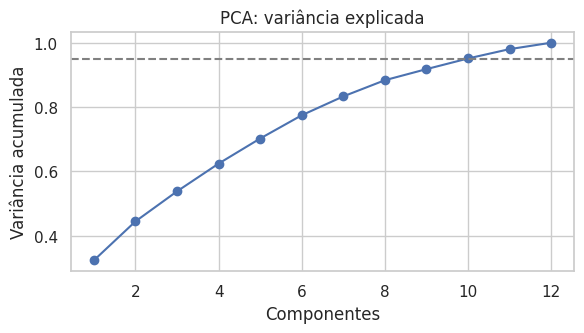

In [16]:
# quais meses a seleção escolheu? (ajustado em todos os dados só para olhar; não entra na avaliação)
Xi = StandardScaler().fit_transform(SimpleImputer(strategy='median').fit_transform(X[X.isna().sum(axis=1) <= 6]))
yi = y[X.isna().sum(axis=1) <= 6]
sk = SelectKBest(f_classif, k=6).fit(Xi, yi)
print("SelectKBest (6) escolheu:", [m for m, s in zip(MESES, sk.get_support()) if s])
sfs = SequentialFeatureSelector(KNeighborsClassifier(5), n_features_to_select=6, cv=3, n_jobs=-1).fit(Xi, yi)
print("SequentialFeatureSelector (6) escolheu:", [m for m, s in zip(MESES, sfs.get_support()) if s])

pca = PCA().fit(Xi)
plt.figure(figsize=(6, 3.5))
plt.plot(range(1, 13), np.cumsum(pca.explained_variance_ratio_), marker='o')
plt.axhline(0.95, color='gray', ls='--'); plt.xlabel('Componentes'); plt.ylabel('Variância acumulada')
plt.title('PCA: variância explicada'); plt.tight_layout(); plt.show()

## 7. Balanceamento de classes (Aula 8)

**O que fazemos:** testamos reamostragem para ajudar a classe pequena (São Francisco, ~8%). **Por quê:** o `KNeighborsClassifier` **não tem** `class_weight`, então a saída é reamostrar. **Regra:** a reamostragem é feita **só no treino de cada fold** (o teste continua com a distribuição real), depois de imputar e normalizar. Medimos o efeito no F1 e no recall do São Francisco: normalmente o recall sobe e a precisão cai (troca precisão × recall).

In [17]:
try:
    from imblearn.over_sampling import RandomOverSampler, SMOTE
    from imblearn.under_sampling import RandomUnderSampler
    print("usando imbalanced-learn")
except ImportError:
    print("imbalanced-learn não encontrado: usando versões simples dos reamostradores")
    class RandomOverSampler:
        def __init__(self, random_state=0): self.rs = np.random.RandomState(random_state)
        def fit_resample(self, X, y):
            X, y = np.asarray(X), np.asarray(y); alvo = pd.Series(y).value_counts().max()
            Xs, ys = [X], [y]
            for c, n in pd.Series(y).value_counts().items():
                if n < alvo:
                    idx = self.rs.choice(np.where(y == c)[0], alvo - n, replace=True); Xs.append(X[idx]); ys.append(y[idx])
            return np.vstack(Xs), np.concatenate(ys)
    class RandomUnderSampler:
        def __init__(self, random_state=0): self.rs = np.random.RandomState(random_state)
        def fit_resample(self, X, y):
            X, y = np.asarray(X), np.asarray(y); alvo = pd.Series(y).value_counts().min(); idx = []
            for c in np.unique(y): idx += list(self.rs.choice(np.where(y == c)[0], alvo, replace=False))
            return X[idx], y[idx]
    class SMOTE:
        def __init__(self, k_neighbors=5, random_state=0): self.k = k_neighbors; self.rs = np.random.RandomState(random_state)
        def fit_resample(self, X, y):
            X, y = np.asarray(X), np.asarray(y); alvo = pd.Series(y).value_counts().max(); Xs, ys = [X], [y]
            for c, n in pd.Series(y).value_counts().items():
                if n < alvo:
                    Xc = X[y == c]; k = min(self.k, len(Xc) - 1)
                    viz = NearestNeighbors(n_neighbors=k + 1).fit(Xc).kneighbors(Xc, return_distance=False)[:, 1:]
                    i = self.rs.randint(0, len(Xc), alvo - n); j = viz[i, self.rs.randint(0, k, alvo - n)]
                    lam = self.rs.rand(alvo - n, 1); Xs.append(Xc[i] + lam * (Xc[j] - Xc[i])); ys.append(np.full(alvo - n, c))
            return np.vstack(Xs), np.concatenate(ys)

usando imbalanced-learn


In [18]:
def avaliar_amostragem(sampler, rotulo, imp=None, sc=None, max_aus=6):
    # imputa e normaliza com o treino, reamostra SÓ o treino, treina o KNN e testa no fold intacto
    imp = imp or (lambda: SimpleImputer(strategy='median')); sc = sc or StandardScaler
    Xf, yf, gf = filtrar(X, y, g, max_aus)
    f1s, accs, bals = [], [], []
    pred = pd.Series(index=yf.index, dtype=object)
    for tr, te in cv.split(Xf, yf, gf):
        i_, s_ = imp(), sc()
        Xtr = s_.fit_transform(i_.fit_transform(Xf.iloc[tr])); Xte = s_.transform(i_.transform(Xf.iloc[te]))
        ytr = yf.iloc[tr].to_numpy()
        if sampler is not None:
            Xtr, ytr = sampler.fit_resample(Xtr, ytr)
        p = knn_base().fit(Xtr, ytr).predict(Xte)
        pred.iloc[te] = p
        from sklearn.metrics import f1_score, accuracy_score, balanced_accuracy_score
        f1s.append(f1_score(yf.iloc[te], p, average='macro')); accs.append(accuracy_score(yf.iloc[te], p))
        bals.append(balanced_accuracy_score(yf.iloc[te], p))
    return metricas(yf, pred.to_numpy(), f1s, accs, bals, rotulo, len(Xf))

linhas = [avaliar_amostragem(None, 'Sem reamostrar (base v1)'),
          avaliar_amostragem(RandomOverSampler(random_state=SEED), 'RandomOverSampler'),
          avaliar_amostragem(RandomUnderSampler(random_state=SEED), 'RandomUnderSampler'),
          avaliar_amostragem(SMOTE(k_neighbors=3, random_state=SEED), 'SMOTE (k=3)'),
          avaliar_amostragem(SMOTE(k_neighbors=5, random_state=SEED), 'SMOTE (k=5)')]
registrar(linhas, '7. Balanceamento')

,config,n_instancias,acc,f1_macro,f1_std,f1_SF,recall_SF
0,Sem reamostrar (base v1),3337,0.753,0.718,0.012,0.519,0.470
1,RandomOverSampler,3337,0.701,0.681,0.025,0.514,0.690
2,RandomUnderSampler,3337,0.661,0.642,0.033,0.485,0.731
3,SMOTE (k=3),3337,0.706,0.687,0.026,0.522,0.705
4,SMOTE (k=5),3337,0.705,0.685,0.026,0.523,0.713


**Como ler:** olhe `f1_SF` e `recall_SF` junto com `f1_macro`. Se o recall do São Francisco sobe, mas o `f1_macro` e a acurácia caem, há uma troca: ganhamos na classe pequena e perdemos nas grandes. Vale discutir qual objetivo importa mais.

## 8. Pipeline final combinado e tabela geral

**O que fazemos:** juntamos as melhores escolhas e rodamos de novo, porque cada tema foi testado separado e os efeitos podem não se somar. **Edite a lista abaixo** com o que ganhou nas seções 2 a 7.

In [19]:
# Combinações candidatas (ajuste conforme as tabelas acima)
zero = lambda: SimpleImputer(strategy='constant', fill_value=0)
linhas = [
    avaliar(pipe_base(), rotulo='BASE V1'),
    avaliar(pipe_imp(SimpleImputer(strategy='constant', fill_value=0)), rotulo='Final A: imputar 0'),
    avaliar(pipe_imp(SimpleImputer(strategy='constant', fill_value=0), sc=RobustScaler), rotulo='Final B: imputar 0 + Robust'),
    avaliar_amostragem(SMOTE(k_neighbors=5, random_state=SEED), 'Final C: imputar 0 + SMOTE', imp=zero),
    avaliar_amostragem(RandomOverSampler(random_state=SEED), 'Final D: imputar 0 + oversampling', imp=zero),
]
registrar(linhas, '8. Combinações')

,config,n_instancias,acc,f1_macro,f1_std,f1_SF,recall_SF
0,BASE V1,3337,0.753,0.718,0.012,0.519,0.470
1,Final A: imputar 0,3337,0.777,0.745,0.021,0.579,0.560
2,Final B: imputar 0 + Robust,3337,0.775,0.743,0.020,0.578,0.552
3,Final C: imputar 0 + SMOTE,3337,0.730,0.706,0.036,0.535,0.750
4,Final D: imputar 0 + oversampling,3337,0.723,0.696,0.034,0.525,0.735


,secao,config,n_instancias,acc,f1_macro,f1_std,f1_SF,recall_SF
6,2. Ausentes,"Constante 0, até 4 meses vazios",3086,0.788,0.758,0.022,0.624,0.628
16,4. Encoding,12 meses + Ano em One-Hot,3337,0.792,0.758,0.022,0.594,0.541
7,2. Ausentes,"Constante 0, até 6 meses vazios",3337,0.777,0.745,0.021,0.579,0.560
4,2. Ausentes,"Constante 0 (""-"" = sem chuva)",3337,0.777,0.745,0.021,0.579,0.560
40,8. Combinações,Final A: imputar 0,3337,0.777,0.745,0.021,0.579,0.560
41,8. Combinações,Final B: imputar 0 + Robust,3337,0.775,0.743,0.020,0.578,0.552
9,2. Ausentes,"Constante 0, até 10 meses vazios",3488,0.760,0.729,0.020,0.530,0.524
3,2. Ausentes,KNNImputer(5),3337,0.752,0.722,0.029,0.542,0.526
14,3. Outliers,Limita cada mês a 400 mm,3337,0.756,0.720,0.017,0.528,0.474
11,3. Outliers,Limita cada mês a 800 mm,3337,0.753,0.718,0.012,0.519,0.470


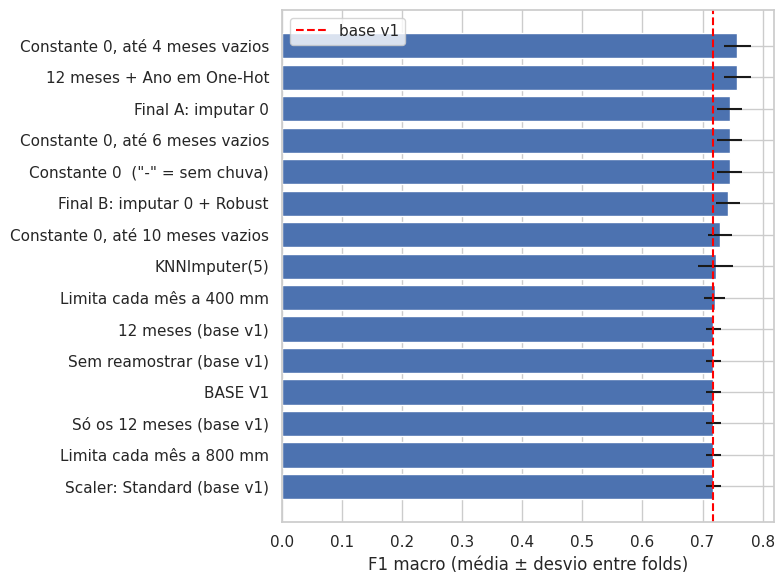

In [20]:
geral = pd.DataFrame(tabela)
geral = geral[['secao', 'config', 'n_instancias', 'acc', 'f1_macro', 'f1_std', 'f1_SF', 'recall_SF']]
geral.to_csv('experimentos_extras.csv', index=False)   # no Colab: baixe pela pasta lateral
display(geral.sort_values('f1_macro', ascending=False).head(10))

top = geral.sort_values('f1_macro', ascending=True).tail(15)
plt.figure(figsize=(8, 6))
plt.barh(top['config'], top['f1_macro'], xerr=top['f1_std'], color='#4C72B0')
plt.axvline(geral.loc[geral['config'].str.contains('BASE V1', regex=False), 'f1_macro'].iloc[0], color='red', ls='--', label='base v1')
plt.xlabel('F1 macro (média ± desvio entre folds)'); plt.legend(); plt.tight_layout(); plt.show()

**Como ler:** diferenças menores que o desvio entre folds (`f1_std`, em torno de 0,02) **não são conclusivas**. Só vale destacar ganhos claros, e sempre dizer a troca: o que melhorou, o que piorou e quanto custou (instâncias descartadas, classes prejudicadas).

**Para o relatório e o pitch:** para cada seção, escreva 2 ou 3 linhas: *o que testamos, o que aconteceu, e a decisão*.